# Loma Skin: what the marketing mix model says

**For:** the marketing team. **Model:** the live baseline, fitted on weekly data from January 2023 to December 2025.

Two terms used throughout:
- **ROAS** (return on ad spend): revenue the model credits to a channel for each dollar spent. It is revenue, not profit.
- **Next-dollar return** (marginal ROAS): what one more dollar would bring in at today's spend. Budget decisions should use this, because each channel gives less per dollar as spend rises.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if not (Path.cwd() / "src").exists() else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, Markdown, display

from marginal_roas import contribution, logistic

# Reference palette, fixed order by channel (validated: scripts/validate_palette.js, light surface)
COLOR = {"meta": "#2a78d6", "google": "#eb6834", "tiktok": "#1baf7a", "email": "#eda100"}
NAME = {"meta": "Meta", "google": "Google", "tiktok": "TikTok", "email": "Email/SMS"}
SURFACE, INK, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#6b6b66", "#e4e3df"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

est = pd.read_csv(ROOT / "results" / "baseline" / "estimates.csv").set_index("channel")
idata = az.from_netcdf(ROOT / "models" / "baseline.nc")
post = idata.posterior.to_dataset() if hasattr(idata.posterior, "to_dataset") else idata.posterior
cd = idata.constant_data.to_dataset() if hasattr(idata.constant_data, "to_dataset") else idata.constant_data
target_scale = float(cd["target_scale"])
spend = cd["channel_data"].to_pandas()
l_max = 8
draws = {v: post[v].stack(s=("chain", "draw")) for v in ("adstock_alpha", "saturation_lam", "saturation_beta")}
show = lambda df: display(HTML(df.to_html(index=False)))
print("Loaded the live baseline model.")

Loaded the live baseline model.


## 1. Return per dollar, by channel

Each dot is the model's best estimate. The line is the range it considers likely (90% interval). Email/SMS spend is too small and too steady for the model to measure, so it is shown as not measured rather than as a number.

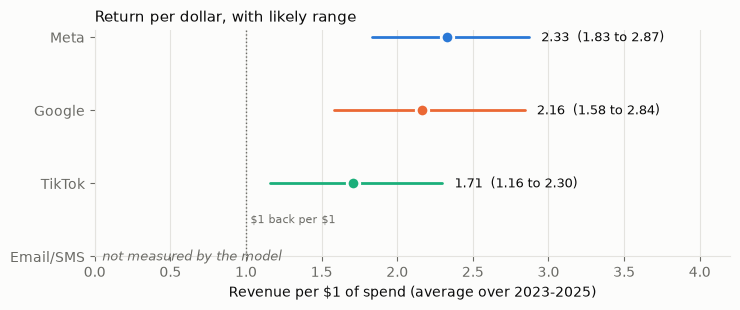

Channel,3-year spend,Return per $1,Likely range
Meta,"$3,760,384",2.33,1.83 to 2.87
Google,"$2,413,442",2.16,1.58 to 2.84
TikTok,"$1,261,376",1.71,1.16 to 2.30
Email/SMS,"$206,154",not measured,


In [2]:
channels = ["meta", "google", "tiktok", "email"]
fig, ax = plt.subplots(figsize=(7.5, 3.2))
for i, ch in enumerate(channels[::-1]):
    r = est.loc[ch]
    if r.reported:
        ax.plot([r.roas_low_5, r.roas_high_95], [i, i], color=COLOR[ch], linewidth=2, solid_capstyle="round")
        ax.plot(r.roas_mean, i, "o", color=COLOR[ch], markersize=9, markeredgecolor=SURFACE, markeredgewidth=2)
        ax.text(r.roas_high_95 + 0.08, i, f"{r.roas_mean:.2f}  ({r.roas_low_5:.2f} to {r.roas_high_95:.2f})",
                va="center", color=INK, fontsize=9)
    else:
        ax.text(0.05, i, "not measured by the model", va="center", color=MUTED, fontsize=9, style="italic")
ax.set_yticks(range(len(channels)))
ax.set_yticklabels([NAME[c] for c in channels[::-1]])
ax.set_xlim(0, 4.2)
ax.set_xlabel("Revenue per $1 of spend (average over 2023-2025)")
ax.axvline(1, color=MUTED, linewidth=1, linestyle=":")
ax.text(1.03, 0.5, r"\$1 back per \$1", color=MUTED, fontsize=8, va="center")
ax.grid(axis="y", visible=False)
ax.set_title("Return per dollar, with likely range", loc="left", fontsize=11)
plt.tight_layout(); plt.show()

table = pd.DataFrame({
    "Channel": [NAME[c] for c in channels],
    "3-year spend": [f"${est.loc[c, 'spend']:,.0f}" for c in channels],
    "Return per $1": [f"{est.loc[c, 'roas_mean']:.2f}" if est.loc[c, "reported"] else "not measured" for c in channels],
    "Likely range": [f"{est.loc[c, 'roas_low_5']:.2f} to {est.loc[c, 'roas_high_95']:.2f}" if est.loc[c, "reported"] else "" for c in channels],
})
show(table)

## 2. How each channel responds to more spend

Each curve shows the weekly revenue the model expects from a steady weekly spend, with its likely range shaded. The dot marks today's average week, and the dashed line marks the biggest week in the data. Where a curve flattens, more spend buys little. The Email/SMS curve is the model's starting assumption, not a measurement.

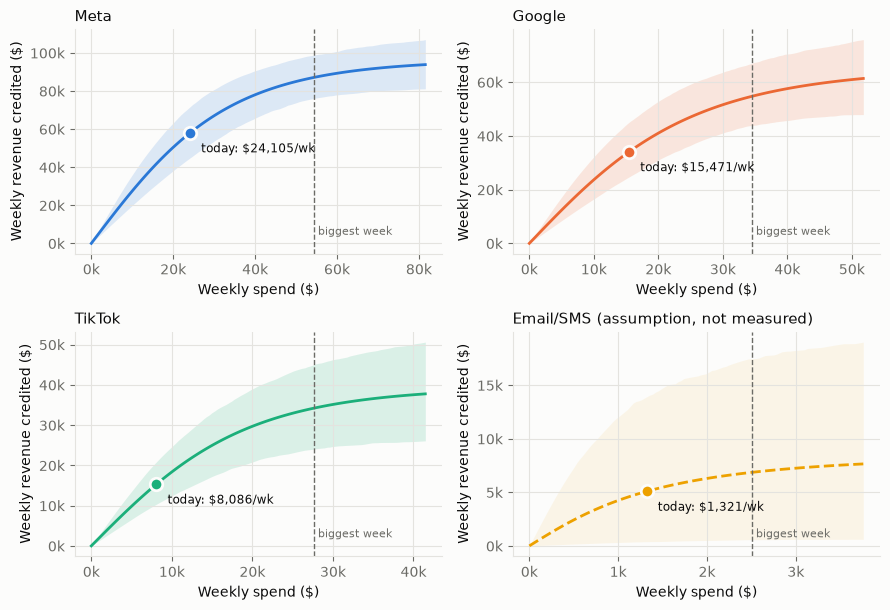

Channel,Average week,Biggest week,Revenue credited in an average week
Meta,"$24,105","$54,377","$57,980"
Google,"$15,471","$34,519","$34,080"
TikTok,"$8,086","$27,644","$15,311"
Email/SMS,"$1,321","$2,506","$5,084"


In [3]:
def curve(ch, grid):
    a = draws["adstock_alpha"].sel(channel=ch).to_numpy()[::4]
    lam = draws["saturation_lam"].sel(channel=ch).to_numpy()[::4]
    beta = draws["saturation_beta"].sel(channel=ch).to_numpy()[::4]
    peak = float(cd["channel_scale"].sel(channel=ch))
    # steady weekly spend s: normalized adstock of a constant is the constant
    y = target_scale * beta[:, None] * logistic(lam[:, None] * grid[None, :] / peak)
    return y.mean(0), np.quantile(y, 0.05, 0), np.quantile(y, 0.95, 0), peak

fig, axes = plt.subplots(2, 2, figsize=(9, 6.2))
rows = []
for ax, ch in zip(axes.ravel(), channels):
    avg = float(spend[ch].mean())
    peak = float(cd["channel_scale"].sel(channel=ch))
    grid = np.linspace(0, 1.5 * peak, 120)
    m, lo, hi, _ = curve(ch, grid)
    measured = bool(est.loc[ch, "reported"])
    ax.fill_between(grid, lo, hi, color=COLOR[ch], alpha=0.15 if measured else 0.08, linewidth=0)
    ax.plot(grid, m, color=COLOR[ch], linewidth=2, linestyle="-" if measured else "--")
    m_avg = curve(ch, np.array([avg]))[0][0]
    ax.plot(avg, m_avg, "o", color=COLOR[ch], markersize=9, markeredgecolor=SURFACE, markeredgewidth=2)
    ax.annotate(f"today: ${avg:,.0f}/wk", (avg, m_avg), textcoords="offset points", xytext=(8, -14), fontsize=8.5)
    ax.axvline(peak, color=MUTED, linewidth=1, linestyle="--")
    ax.text(peak, ax.get_ylim()[1] * 0.04, " biggest week", color=MUTED, fontsize=8)
    ax.set_title(NAME[ch] + ("" if measured else " (assumption, not measured)"), loc="left", fontsize=10.5)
    ax.set_xlabel("Weekly spend ($)")
    ax.set_ylabel("Weekly revenue credited ($)")
    ax.xaxis.set_major_formatter(lambda x, _: f"{x/1000:.0f}k")
    ax.yaxis.set_major_formatter(lambda x, _: f"{x/1000:.0f}k")
    rows.append(dict(Channel=NAME[ch], **{"Average week": f"${avg:,.0f}", "Biggest week": f"${peak:,.0f}",
                     "Revenue credited in an average week": f"${m_avg:,.0f}"}))
plt.tight_layout(); plt.show()
show(pd.DataFrame(rows))

## 3. What this means for budget

In [4]:
def next_dollar(ch):
    lam = draws["saturation_lam"].sel(channel=ch).to_numpy()
    beta = draws["saturation_beta"].sel(channel=ch).to_numpy()
    peak = float(cd["channel_scale"].sel(channel=ch))
    z = lam * float(spend[ch].mean()) / peak
    m = target_scale * beta * lam / peak * 2 * np.exp(-z) / (1 + np.exp(-z)) ** 2
    return m.mean(), np.quantile(m, 0.05), np.quantile(m, 0.95)

nd = {ch: next_dollar(ch) for ch in ["meta", "google", "tiktok"]}
show(pd.DataFrame([{"Channel": NAME[c], "Next $1 returns": f"${v[0]:.2f}",
                    "Likely range": f"${v[1]:.2f} to ${v[2]:.2f}"} for c, v in nd.items()]))

m_, g_ = est.loc["meta"], est.loc["google"]
overlap = m_.roas_low_5 < g_.roas_high_95 and g_.roas_low_5 < m_.roas_high_95
all_above_1 = all(v[0] > 1 for v in nd.values())
lows, highs = [v[1] for v in nd.values()], [v[2] for v in nd.values()]
nd_overlap = max(lows) < min(highs)   # one common value lies in all three ranges
text = f"""
- **At today's spend, {'every paid channel still returns more than $1' if all_above_1 else 'not every paid channel returns more than $1'} of revenue for the next $1**: Meta ${nd['meta'][0]:.2f}, Google ${nd['google'][0]:.2f}, TikTok ${nd['tiktok'][0]:.2f}. Whether that is profitable depends on the product margin, which the model does not know.
{'- **The three are close.** Their likely ranges overlap, so the model does not say clearly that one channel is the better next home for budget. Treat a shift of budget between them as a test, not a certainty.' if nd_overlap else '- **The ranges do not all overlap.** Compare them in the table before moving budget.'}
- **Meta vs Google:** {'their likely ranges overlap' if overlap else 'their ranges do not overlap'} (Meta {m_.roas_low_5:.2f} to {m_.roas_high_95:.2f}, Google {g_.roas_low_5:.2f} to {g_.roas_high_95:.2f}). The model's ranking of the two should not drive a budget move on its own. A holdout or lift test would settle it.
- **Email/SMS is not measured.** Keep its budget on other evidence (for example, a holdout test) until the model can measure it.
"""
display(Markdown(text))

Channel,Next $1 returns,Likely range
Meta,$1.71,$1.48 to $1.93
Google,$1.71,$1.35 to $2.08
TikTok,$1.66,$1.14 to $2.21



- **At today's spend, every paid channel still returns more than $1 of revenue for the next $1**: Meta $1.71, Google $1.71, TikTok $1.66. Whether that is profitable depends on the product margin, which the model does not know.
- **The three are close.** Their likely ranges overlap, so the model does not say clearly that one channel is the better next home for budget. Treat a shift of budget between them as a test, not a certainty.
- **Meta vs Google:** their likely ranges overlap (Meta 1.83 to 2.87, Google 1.58 to 2.84). The model's ranking of the two should not drive a budget move on its own. A holdout or lift test would settle it.
- **Email/SMS is not measured.** Keep its budget on other evidence (for example, a holdout test) until the model can measure it.


## 4. The five data and model problems we investigated

Each one was found, explained and fixed in a test copy. Monitor v2 now catches all five before the model runs.

| Case | What happened, in plain words | What it would have done to the numbers | Fix |
|---|---|---|---|
| Spring sale (Apr 2025) | A two-week sale was missing from the promo calendar. | The model mistook the sale's lift for Meta's effect. Meta looked worse on average, but its curve suggested it could take far more budget. | Add the sale back. The marketing team signs off the promo calendar each month. |
| Meta campaign relaunch | A relaunched Meta campaign got the wrong label, so about $197K of Meta spend never reached the model. | TikTok looked about half as effective as it is. Cost per new customer since September read too low. | Correct the label. New campaigns are reviewed before each refresh. |
| Late Shopify data | Sales stopped loading 9 days before ad spend did. | The latest week's cost per new customer read about 38% too high. | Reload the missing days. Refreshes wait until all sources are up to date. |
| TikTok feed gap | TikTok spend for 3 weeks in June 2025 never loaded, but the sales it drove did. | TikTok was rated about 13% lower, with a much wider range. | Re-pull those weeks from TikTok Ads Manager. |
| Model setting change | A model setting was changed without a record. | Meta, Google and TikTok barely moved. Email's curve would have told a budget tool to cut email. | Revert the setting. Any setting change now needs a record and a pre-check. |

Full investigation notes are in the `alerts/` folder.